<a href="https://colab.research.google.com/github/zhannakhu96/E-commerce-Sales-analysis-project/blob/main/Updated_ecommerce_sales_customer_analysis_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q pandas numpy matplotlib seaborn openpyxl

# E-commerce Sales & Customer Analysis

**Portfolio project | Python · Pandas · Matplotlib · Seaborn · RFM analysis**

## Business objective
Analyse historical transactions from a UK-based online retailer to understand revenue trends, product performance, geographic performance, and customer value.

## Dataset
UCI Machine Learning Repository — [Online Retail](https://archive.ics.uci.edu/dataset/352/online-retail), 541,909 transaction-line records covering 1 December 2010 to 9 December 2011.

**Attribution:** Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33. Licensed under CC BY 4.0.

> Important: This notebook is designed to run end-to-end after downloading the Excel file or fetching it with `ucimlrepo`. The dataset could not be downloaded into this chat's execution environment, so no results are fabricated. Run the notebook to calculate the real figures.


## 1. Setup and load data

In [2]:
# Setup and load the original UCI Online Retail dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

REQUIRED_COLUMNS = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
DATA_PATH = Path("data/Online Retail.xlsx")
UCI_DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

def download_uci_online_retail():
    """Download the official UCI ZIP and read its original Excel workbook."""
    with urlopen(UCI_DATA_URL, timeout=60) as response:
        archive_bytes = response.read()

    with ZipFile(BytesIO(archive_bytes)) as archive:
        excel_files = [
            name for name in archive.namelist()
            if name.lower().endswith((".xlsx", ".xls"))
        ]
        if not excel_files:
            raise FileNotFoundError("No Excel workbook was found in the UCI ZIP archive.")
        with archive.open(excel_files[0]) as workbook:
            return pd.read_excel(workbook, engine="openpyxl")

# Use a local workbook only if it contains all eight original fields.
raw = None
if DATA_PATH.exists():
    local_data = pd.read_excel(DATA_PATH, engine="openpyxl")
    local_data.columns = local_data.columns.astype(str).str.strip()
    if set(REQUIRED_COLUMNS).issubset(local_data.columns):
        raw = local_data
    else:
        print("Local workbook is missing required columns; downloading the official UCI file.")

if raw is None:
    raw = download_uci_online_retail()

raw.columns = raw.columns.astype(str).str.strip()
missing_columns = [column for column in REQUIRED_COLUMNS if column not in raw.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")
raw = raw[REQUIRED_COLUMNS].copy()

print(f"Dataset shape: {raw.shape}")
print("Columns:", raw.columns.tolist())
display(raw.head())
raw.info()

Dataset shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## 2. Data quality assessment

In [3]:
# Initial data-quality assessment
print(f"Duplicate rows: {raw.duplicated().sum():,}")
missing_summary = raw.isna().sum().sort_values(ascending=False).to_frame("missing_values")
display(missing_summary)
display(raw.describe(include="all").T)

Duplicate rows: 5,268


,missing_values
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,"541,909.00","25,900.00","573,585.00","1,114.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning and revenue calculation

Cleaning decisions:
- Remove exact duplicate transaction lines.
- Exclude rows without a customer ID from customer-level segmentation (retain a separate copy for sales-level checks if desired).
- Exclude cancellation invoices (invoice numbers beginning with `C`) from completed-sales analysis.
- Exclude non-positive quantities and unit prices from completed-sales revenue analysis.
- Parse invoice dates and calculate line revenue as `Quantity × UnitPrice`.

These rules define a completed-sales view; returns/cancellations are not treated as positive sales.


In [4]:
# Clean transaction lines and calculate completed-sales revenue
df = raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["StockCode"] = df["StockCode"].astype("string").str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

# In this dataset, cancelled invoices have an InvoiceNo beginning with C.
df["is_cancellation"] = df["InvoiceNo"].str.upper().str.startswith("C", na=False)
deduplicated = df.drop_duplicates().copy()

# Do not create placeholder invoice numbers: missing IDs must not become fake orders.
clean = deduplicated[
    deduplicated["InvoiceNo"].notna()
    & deduplicated["InvoiceDate"].notna()
    & (~deduplicated["is_cancellation"])
    & deduplicated["Quantity"].gt(0)
    & deduplicated["UnitPrice"].gt(0)
].copy()

clean["Revenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["YearMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()

print(f"Original rows: {len(raw):,}")
print(f"Rows after exact-deduplication: {len(deduplicated):,}")
print(f"Completed-sales rows: {len(clean):,}")
print(f"Rows excluded from completed-sales view: {len(raw) - len(clean):,}")
print(f"Cancellation rows in original data: {int(df['is_cancellation'].sum()):,}")
print(f"Unique invoices: {clean['InvoiceNo'].nunique():,}")
print(f"Unique identified customers: {clean['CustomerID'].nunique():,}")
print(f"Completed-sales revenue (£): {clean['Revenue'].sum():,.2f}")
display(clean.head())

Original rows: 541,909
Rows after exact-deduplication: 536,641
Completed-sales rows: 524,878
Rows excluded from completed-sales view: 17,031
Cancellation rows in original data: 9,288
Unique invoices: 19,960
Unique identified customers: 4,338
Completed-sales revenue (£): 10,642,110.80


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,is_cancellation,Revenue,YearMonth,Weekday
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom,False,15.30,2010-12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,20.34,2010-12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom,False,22.00,2010-12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,20.34,2010-12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom,False,20.34,2010-12,Wednesday


## 3. Data cleaning and revenue calculation

Cleaning decisions:
- Remove exact duplicate transaction lines.
- Exclude cancelled invoices, invalid dates, missing invoice numbers, and non-positive quantity or unit price.
- Retain rows with missing CustomerID for overall sales reporting; exclude them only from customer-level RFM analysis.
- Calculate line revenue as Quantity × UnitPrice. This is sales revenue, not profit.


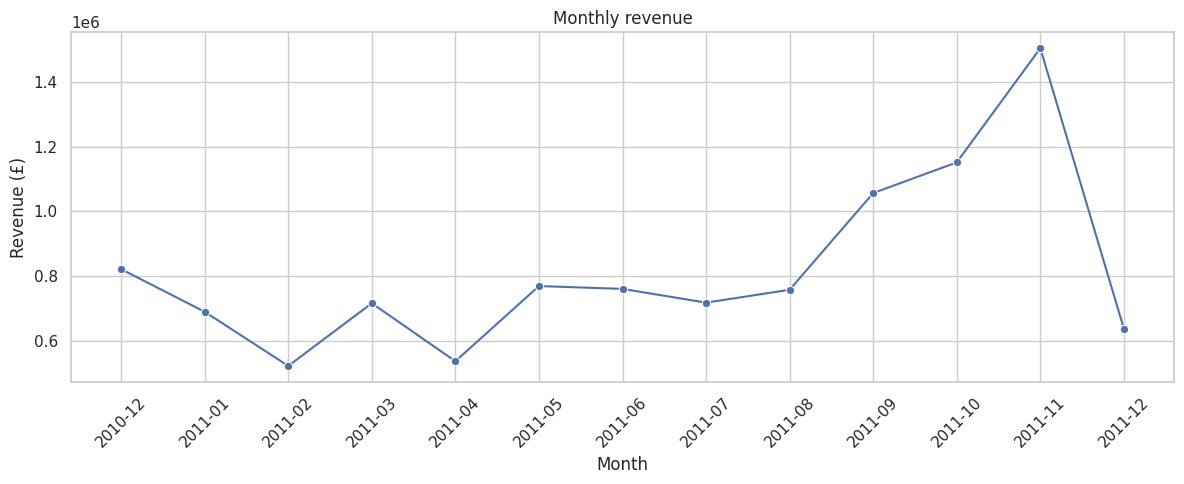

,YearMonth,Revenue,Orders,Units
11,2011-11,"1,503,866.78",2769,751377
10,2011-10,"1,151,263.73",2040,621029
9,2011-09,"1,056,435.19",1837,569573
0,2010-12,"821,452.73",1559,358019
5,2011-05,"769,296.61",1681,395001


In [5]:
monthly = clean.groupby("YearMonth", as_index=False).agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Units=("Quantity", "sum")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="YearMonth", y="Revenue", marker="o")
plt.title("Monthly revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly.sort_values("Revenue", ascending=False).head(5))

## 5. Product performance

,Units_Sold,Revenue,Orders
Description,,,
DOTCOM POSTAGE,706,"206,248.77",706
REGENCY CAKESTAND 3 TIER,13851,"174,156.54",1988
"PAPER CRAFT , LITTLE BIRDIE",80995,"168,469.60",1
WHITE HANGING HEART T-LIGHT HOLDER,37872,"106,236.72",2256
PARTY BUNTING,18283,"99,445.23",1685
JUMBO BAG RED RETROSPOT,48371,"94,159.81",2089
MEDIUM CERAMIC TOP STORAGE JAR,78033,"81,700.92",247
POSTAGE,3150,"78,101.88",1126
Manual,6985,"77,752.82",290


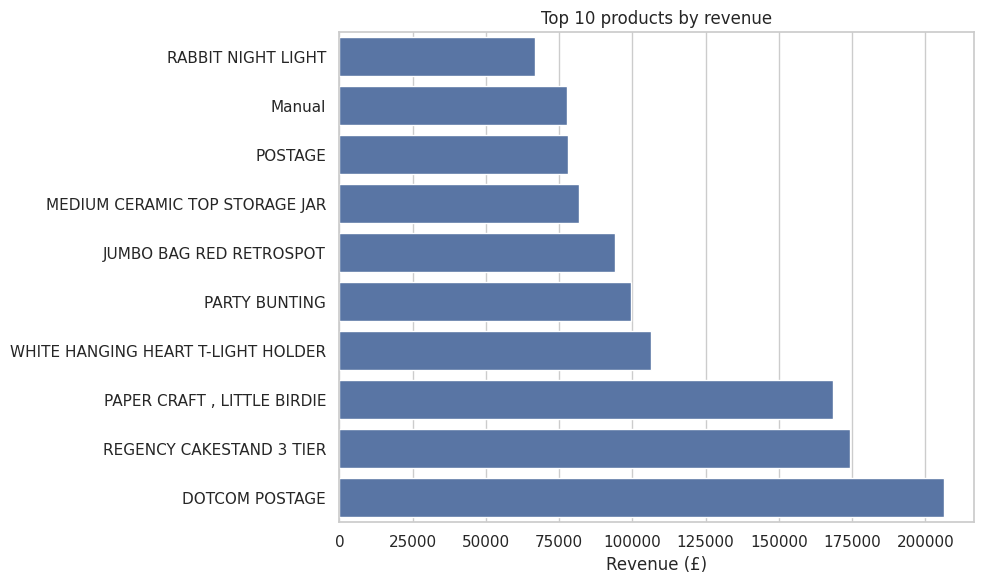

In [6]:
product_perf = clean.groupby("Description", dropna=True).agg(
    Units_Sold=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique")
).sort_values("Revenue", ascending=False)

display(product_perf.head(10))

top_products = product_perf.head(10).sort_values("Revenue")
plt.figure(figsize=(10, 6))
sns.barplot(data=top_products.reset_index(), x="Revenue", y="Description")
plt.title("Top 10 products by revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Country performance

,Revenue,Orders,Customers
Country,,,
United Kingdom,"9,001,744.09",18019,3920
Netherlands,"285,446.34",94,9
EIRE,"283,140.52",288,3
Germany,"228,678.40",457,94
France,"209,625.37",392,87
Australia,"138,453.81",57,9
Spain,"61,558.56",90,30
Switzerland,"57,067.60",54,21
Belgium,"41,196.34",98,25


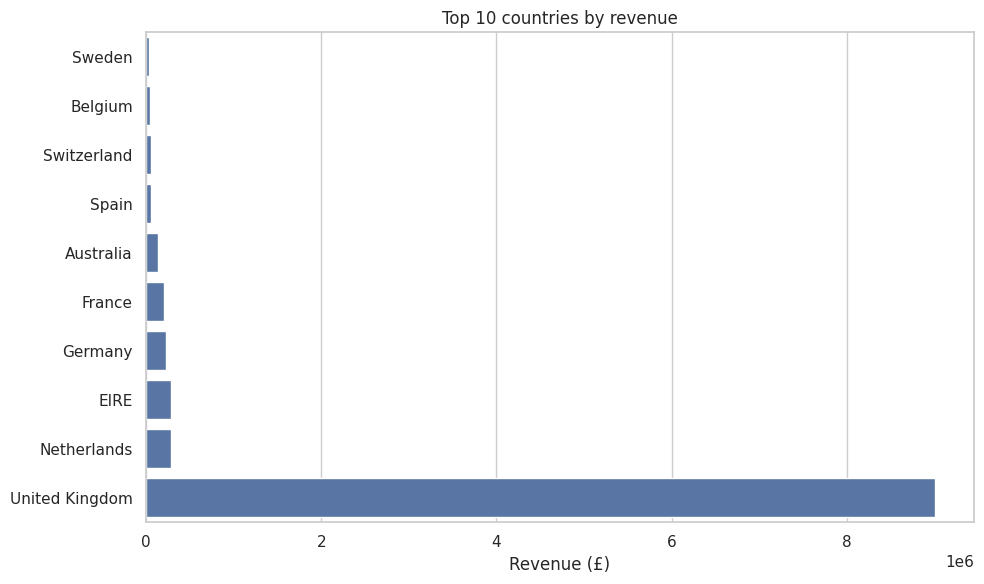

In [7]:
country_perf = clean.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique")
).sort_values("Revenue", ascending=False)

display(country_perf.head(10))

top_countries = country_perf.head(10).sort_values("Revenue")
plt.figure(figsize=(10, 6))
sns.barplot(data=top_countries.reset_index(), x="Revenue", y="Country")
plt.title("Top 10 countries by revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 7. Customer analysis: RFM segmentation

RFM means:
- **Recency:** days since the customer's most recent purchase (lower is better).
- **Frequency:** number of distinct invoices (higher is better).
- **Monetary:** total recorded revenue (higher is better).

The reference date is set to one day after the latest invoice date in the dataset, making the calculation reproducible for this historical dataset.


In [8]:
# RFM customer segmentation: Recency, Frequency, Monetary value
# Customers without a CustomerID are excluded from customer-level analysis only.
customer_data = clean.dropna(subset=["CustomerID"]).copy()
if customer_data.empty:
    raise ValueError("No identified customers remain; RFM analysis cannot be calculated.")

reference_date = customer_data["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = customer_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (reference_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

# Rank values before qcut to handle ties while forming five approximately equal groups.
rfm["R"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm[["R", "F", "M"]].sum(axis=1)

def segment_customer(row):
    if row["R"] >= 4 and row["F"] >= 4 and row["M"] >= 4:
        return "Best customers"
    if row["R"] >= 3 and row["F"] >= 3:
        return "Loyal / engaged"
    if row["R"] <= 2 and row["F"] >= 3:
        return "At risk"
    if row["F"] <= 2:
        return "New / occasional"
    return "Potential loyalists"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
display(rfm.head())
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Total_Monetary=("Monetary", "sum")
).sort_values("Customers", ascending=False)
display(segment_summary)

,Recency,Frequency,Monetary,R,F,M,RFM_Score,Segment
CustomerID,,,,,,,,
"12,346.00",326,1,"77,183.60",1,1,5,7,New / occasional
"12,347.00",2,7,"4,310.00",5,5,5,15,Best customers
"12,348.00",75,4,"1,797.24",2,4,4,10,At risk
"12,349.00",19,1,"1,757.55",4,1,4,9,New / occasional
"12,350.00",310,1,334.40,1,1,2,4,New / occasional


,Customers,Average_Recency,Average_Frequency,Total_Monetary
Segment,,,,
New / occasional,1735,147.98,1.14,"824,650.00"
Loyal / engaged,1000,33.32,3.75,"1,500,694.33"
Best customers,942,12.50,11.20,"5,737,952.12"
At risk,661,150.64,3.41,"823,912.44"


## 8. Key performance indicators

In [9]:
# Key performance indicators
# Order value uses completed invoice totals; customer revenue uses identified customers only.
customer_data = clean.dropna(subset=["CustomerID"]).copy()
order_revenue = clean.groupby("InvoiceNo")["Revenue"].sum()
customer_revenue = customer_data.groupby("CustomerID")["Revenue"].sum()

kpis = {
    "Total completed-sales revenue (£)": clean["Revenue"].sum(),
    "Unique completed orders": clean["InvoiceNo"].nunique(),
    "Unique identified customers": clean["CustomerID"].nunique(),
    "Average order value (£)": order_revenue.mean(),
    "Average revenue per identified customer (£)": customer_revenue.mean(),
    "Average units per order": clean.groupby("InvoiceNo")["Quantity"].sum().mean()
}
kpi_results = pd.Series(kpis, name="Value").to_frame()
display(kpi_results)

,Value
Total completed-sales revenue (£),"10,642,110.80"
Unique completed orders,"19,960.00"
Unique identified customers,"4,338.00"
Average order value (£),533.17
Average revenue per identified customer (£),"2,048.69"
Average units per order,279.18


## 9. Findings and recommendations — complete after running

Use the calculated outputs above to write evidence-based conclusions. Do not fill this section with assumptions.

Suggested questions:
1. Which month had the highest revenue, and what might explain the peak?
2. Is revenue concentrated in a small number of products or countries?
3. How large is the best-customer segment?
4. Which customers appear at risk based on recency?
5. What practical action should the retailer take?

## Limitations
- This is historical data from one retailer, not a current market benchmark.
- Revenue is calculated from transaction line quantity multiplied by unit price; it is not necessarily net profit.
- The completed-sales view excludes cancellations and non-positive quantity/price rows. Returns are therefore not analysed as a separate process here.
- RFM segment labels are rule-based illustrative groupings, not ground-truth customer labels.
